In [1]:
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt

In [2]:
ingredients = ["Pork", "Wheat", "Starch"]
sausages = ["Economy", "Premium"]
cost = [4.32, 2.46, 1.86]           # €/kg
availability = [30, 20, 17]         # kg
sausage_weight = 0.05               # kg per sausage
demand = [350 * sausage_weight, 500 * sausage_weight]   # kg: [17.5, 25]
min_pork = [0.4, 0.6]
max_starch = 0.25
pork_bought = 23

In [3]:
def solve_blending(ingredients, sausages, cost, availability, demand, min_pork, max_starch, pork_bought):
    cost = np.asarray(cost, dtype=float)
    availability = np.asarray(availability, dtype=float)
    demand = np.asarray(demand, dtype=float)
    min_pork = np.asarray(min_pork, dtype=float)

    model = pulp.LpProblem("Blending", pulp.LpMinimize)

    x = model.add_variable_dict("x", (ingredients, sausages), lowBound=0, cat="Continuous")

    model += pulp.lpSum(cost[i] * x[ing, s] for i, ing in enumerate(ingredients) for s in sausages)

    # constraints
    for j, s in enumerate(sausages):
        total = pulp.lpSum(x[ing, s] for ing in ingredients)
        model += total == demand[j], f"Demand_{s}"
        model += x["Pork", s] >= min_pork[j] * total, f"Min_pork_{s}"
        model += x["Starch", s] <= max_starch * total, f"Max_starch_{s}"

    for i, ing in enumerate(ingredients):
        model += pulp.lpSum(x[ing, s] for s in sausages) <= availability[i], f"Availability_{ing}"

    model += pulp.lpSum(x["Pork", s] for s in sausages) >= pork_bought, "Use_bought_pork"

    result = model.solve(pulp.HiGHS(msg=False))
    return model, x, result

In [4]:
model, x, result = solve_blending(ingredients, sausages, cost, availability, demand, min_pork, max_starch, pork_bought)
if result.status_str == "Optimal":
    recipe = pd.DataFrame(
        [[x[ing, s].value() for s in sausages] for ing in ingredients],
        index=ingredients, columns=sausages,
    )
    print("Optimal recipe (kg):")
    print(recipe)
    print("\nShare of each ingredient:")
    print((recipe / recipe.sum()).round(3))
    print("\nTotal Cost:", round(result.objective, 3), "€")

Optimal recipe (kg):
        Economy  Premium
Pork      8.000    15.00
Wheat     5.125     3.75
Starch    4.375     6.25

Share of each ingredient:
        Economy  Premium
Pork      0.457     0.60
Wheat     0.293     0.15
Starch    0.250     0.25

Total Cost: 140.955 €


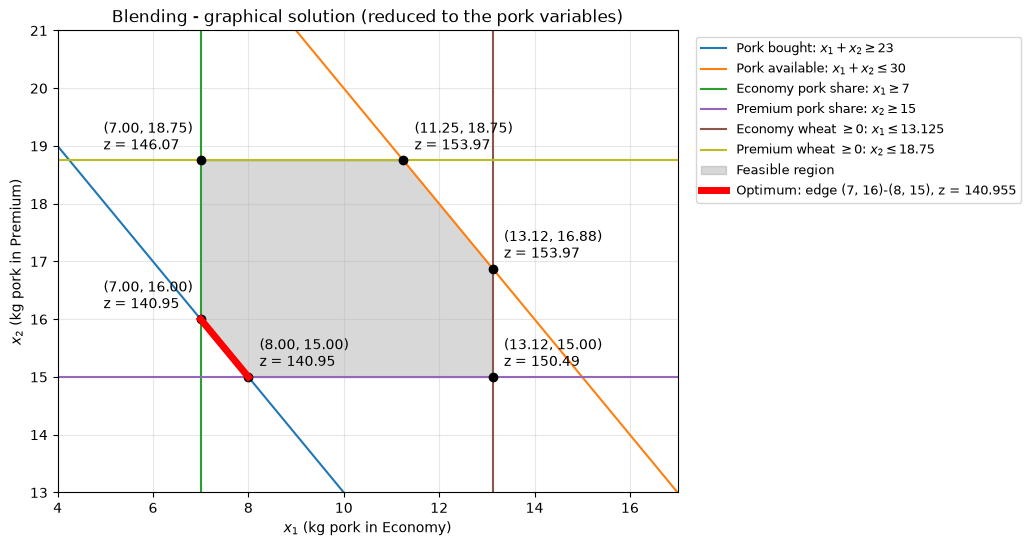

In [5]:
x1 = np.linspace(4, 17, 400)

# Each constraint written as x2 = ... (its boundary line)
# x1 = kg pork in Economy, x2 = kg pork in Premium (starch fixed at 25 %, wheat fills the rest)
pork_bought = 23 - x1             # x1 + x2 >= 23
pork_available = 30 - x1          # x1 + x2 <= 30

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Constraint boundary lines
ax.plot(x1, pork_bought, label=r"Pork bought: $x_1 + x_2 \geq 23$")
ax.plot(x1, pork_available, label=r"Pork available: $x_1 + x_2 \leq 30$")
ax.axvline(7, color="tab:green", label=r"Economy pork share: $x_1 \geq 7$")
ax.axhline(15, color="tab:purple", label=r"Premium pork share: $x_2 \geq 15$")
ax.axvline(13.125, color="tab:brown", label=r"Economy wheat $\geq 0$: $x_1 \leq 13.125$")
ax.axhline(18.75, color="tab:olive", label=r"Premium wheat $\geq 0$: $x_2 \leq 18.75$")

# 2. Feasible region: between the two pork lines and inside the four bounds
x1_feasible = np.linspace(7, 13.125, 200)
lower = np.maximum(15, 23 - x1_feasible)
upper = np.minimum(18.75, 30 - x1_feasible)
ax.fill_between(x1_feasible, lower, upper, color="grey", alpha=0.3, label="Feasible region")

# 3. Corner points of the feasible region and the cost at each
corners = [(8, 15), (13.125, 15), (13.125, 16.875), (11.25, 18.75), (7, 18.75), (7, 16)]
for cx, cy in corners:
    z = 98.175 + 1.86 * (cx + cy)
    ax.plot(cx, cy, "ko", clip_on=False)
    ax.annotate(f"({cx:.2f}, {cy:.2f})\nz = {z:.2f}", (cx, cy), textcoords="offset points", xytext=(8, 8) if cx > 7.5 else (-70, 8))

# 4. Optimum: every point on the edge from (7, 16) to (8, 15)
ax.plot([7, 8], [16, 15], "r-", linewidth=5, label="Optimum: edge (7, 16)-(8, 15), z = 140.955")

ax.set_xlim(4, 17)
ax.set_ylim(13, 21)
ax.set_xlabel("$x_1$ (kg pork in Economy)")
ax.set_ylabel("$x_2$ (kg pork in Premium)")
ax.set_title("Blending - graphical solution (reduced to the pork variables)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
ax.grid(alpha=0.3)
plt.show()